# Quantum Fourier Transform

In [ ]:
pip install qiskit pylatexenc matplotlib qiskit-aer pandas

## Qiskit Implementation<a id='implementation'></a>


### Example on 3 Qubits <a id="threeqft"></a>

In [1]:
import numpy as np
from numpy import pi
# importing Qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_bloch_multivector

It is useful to work out the relevant code for the 3-qubit case before generalizing to the $n$-qubit case. First, we must define our quantum circuit:

In [2]:
qc = QuantumCircuit(3)

**Note**: Remember that Qiskit's least significant bit has the lowest index (0), thus the circuit will be mirrored through the horizontal in relation to the image in section 5. First, we apply a H-gate to qubit 2 :

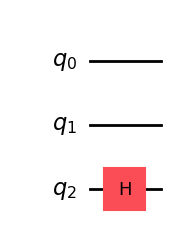

In [3]:
qc.h(2)
qc.draw(output='mpl')

Next, we want to turn this an extra quarter turn if qubit 1 is in the state $|1\rangle$:

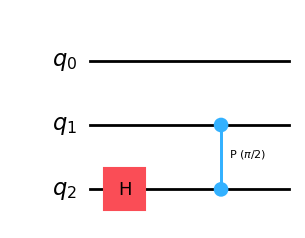

In [4]:
qc.cp(pi/2, 1, 2) # CR from qubit 1 to qubit 2
qc.draw(output='mpl')

And another eighth turn if the least significant qubit (0) is $|1\rangle$:

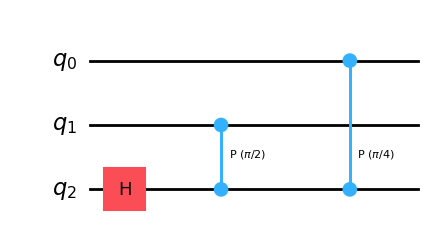

In [5]:
qc.cp(pi/4, 0, 2) # CR from qubit 2 to qubit 0
qc.draw(output='mpl')

With that qubit taken care of, we can now ignore it and repeat the process, using the same logic for qubits 0 and 1:

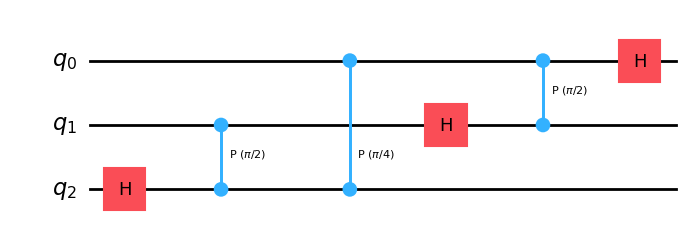

In [6]:
qc.h(1)
qc.cp(pi/2, 0, 1) # CR from qubit 0 to qubit 1
qc.h(0)
qc.draw(output='mpl')

Finally we must swap the qubits 0 and 2 to complete the QFT:

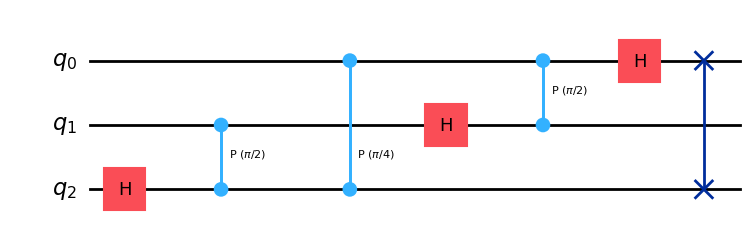

In [7]:
qc.swap(0,2)
qc.draw(output='mpl')

### General QFT Function <a id="generalqft"></a>

We will now create a general circuit for the QFT in Qiskit. Creating large general circuits like this is really where Qiskit shines. 

It is easier to build a circuit that implements the QFT with the qubits upside down, then swap them afterwards; we will start off by creating the function that rotates our qubits correctly. Let’s start as we did with the 3 qubit example, by correctly rotating the most significant qubit (the qubit with the highest index):

In [8]:
def qft_rotations(circuit, n):
    if n == 0: # Exit function if circuit is empty
        return circuit
    n -= 1 # Indexes start from 0
    circuit.h(n) # Apply the H-gate to the most significant qubit
    for qubit in range(n):
        # For each less significant qubit, we need to do a
        # smaller-angled controlled rotation: 
        circuit.cp(pi/2**(n-qubit), qubit, n)

Let’s see how this looks:

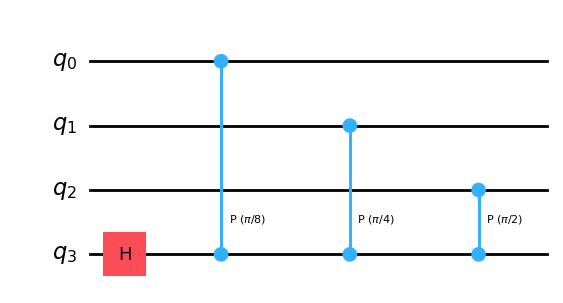

In [9]:
qc = QuantumCircuit(4)
qft_rotations(qc,4)
qc.draw(output='mpl')

Great! This is the first part of our QFT. Now we have correctly rotated the most significant qubit, we need to correctly rotate the second most significant qubit. Then we must deal with the third most significant, and so on. But why write more code? When we get to the end of our `qft_rotations()` function, we can use the same code to repeat the process on the next `n-1` qubits:

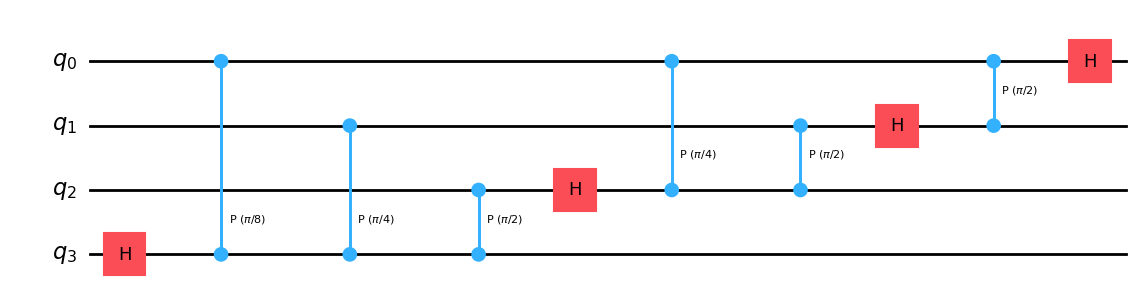

In [10]:
def qft_rotations(circuit, n):
    """Performs qft on the first n qubits in circuit (without swaps)"""
    if n == 0:
        return circuit
    n -= 1
    circuit.h(n)
    for qubit in range(n):
        circuit.cp(pi/2**(n-qubit), qubit, n)
    # At the end of our function, we call the same function again on
    # the next qubits (we reduced n by one earlier in the function)
    qft_rotations(circuit, n)

# Let's see how it looks:
qc = QuantumCircuit(4)
qft_rotations(qc,4)
qc.draw(output='mpl')

That was easy! Process in which a function calls itself directly or indirectly is called _recursion._ It can greatly simplify code.

Finally, we need to add the swaps at the end of the QFT function to match the definition of the QFT. We will combine this into the final function `qft()`:

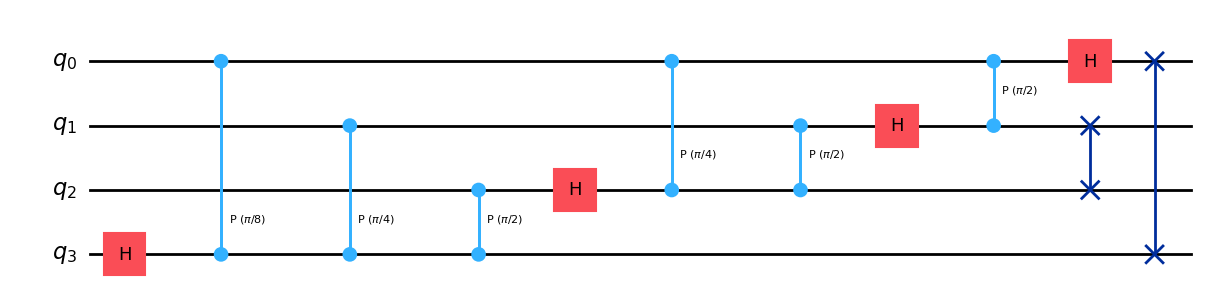

In [11]:
def swap_registers(circuit, n):
    for qubit in range(n//2):
        circuit.swap(qubit, n-qubit-1)
    return circuit

def qft(circuit, n):
    """QFT on the first n qubits in circuit"""
    qft_rotations(circuit, n)
    swap_registers(circuit, n)
    return circuit

# Let's see how it looks:
qc = QuantumCircuit(4)
qft(qc,4)
qc.draw(output='mpl')

This is the generalised circuit for the quantum Fourier transform.

We now want to demonstrate this circuit works correctly. To do this we must first encode a number in the computational basis. We can see the number 5 in binary is `101`:

In [12]:
bin(5)

'0b101'

(The `0b` just reminds us this is a binary number). Let's encode this into our qubits:

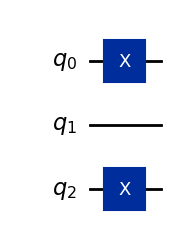

In [13]:
# Create the circuit
qc = QuantumCircuit(3)

# Encode the state 5
qc.x(0)
qc.x(2)
qc.draw(output='mpl')

And let's check the qubit's states using the aer simulator:

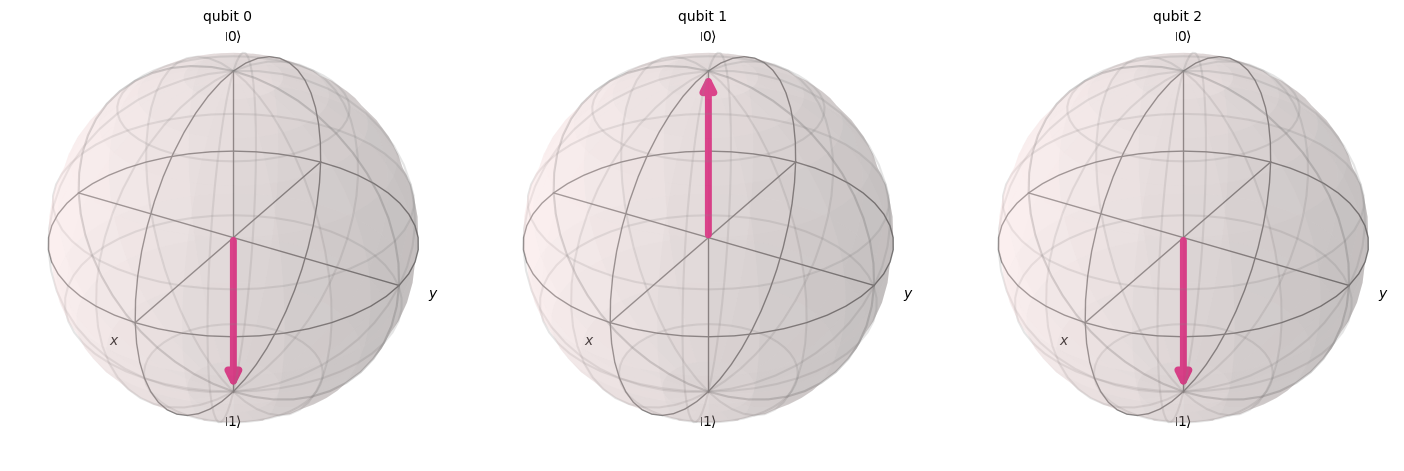

In [14]:
sim = AerSimulator()
qc_init = qc.copy()
qc_init.save_statevector()
statevector = sim.run(qc_init).result().get_statevector()
plot_bloch_multivector(statevector)

Finally, let's use our QFT function and view the final state of our qubits:

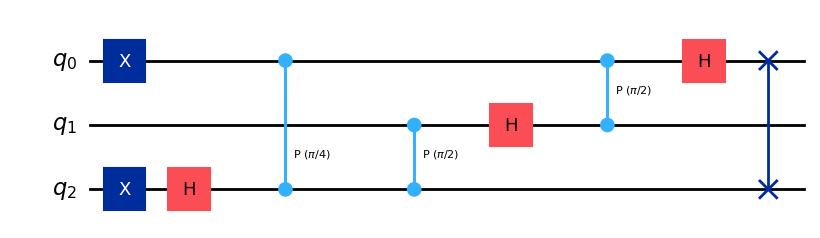

In [15]:
qft(qc,3)
qc.draw(output='mpl')

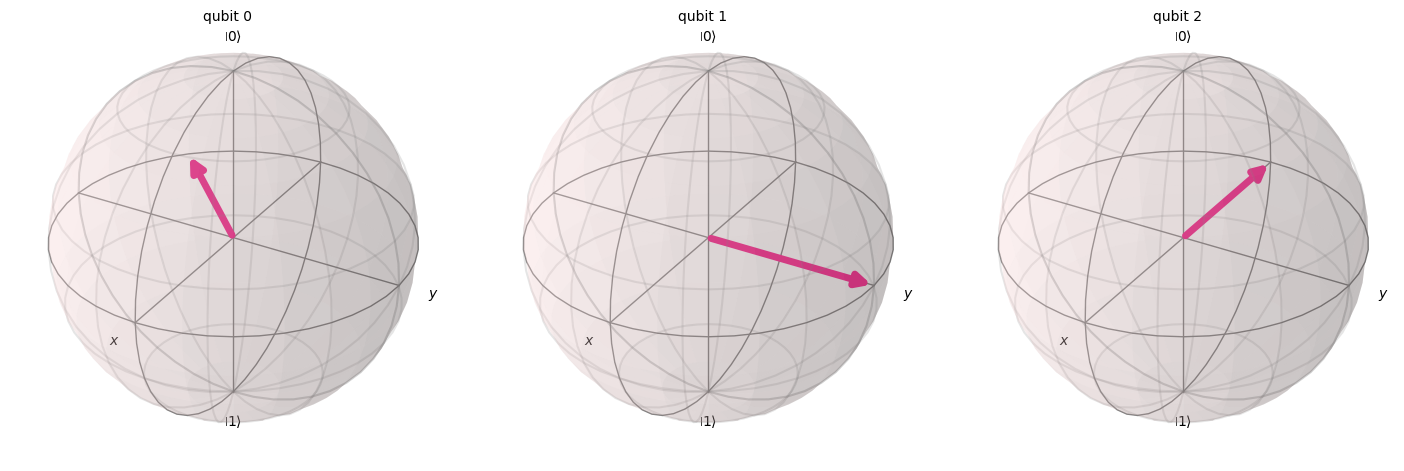

In [16]:
qc.save_statevector()
statevector = sim.run(qc).result().get_statevector()
plot_bloch_multivector(statevector)

We can see out QFT function has worked correctly. Compared the state $|\widetilde{0}\rangle = |{+}{+}{+}\rangle$, Qubit 0 has been rotated by $\tfrac{5}{8}$ of a full turn, qubit 1 by $\tfrac{10}{8}$ full turns (equivalent to $\tfrac{1}{4}$ of a full turn), and qubit 2 by $\tfrac{20}{8}$ full turns (equivalent to $\tfrac{1}{2}$ of a full turn).

### Verifying with Inverse QFT<a id="implementationdev"></a>

If we tried measuring the circuit at the end of the previous section, the results would be completely random, since all qubits are in equal superposition of $|0\rangle$ and $|1\rangle$. If we want to demonstrate and investigate the QFT working, we can instead create the state $|\widetilde{5}\rangle$ seen earlier, run the QFT in reverse, and verify the output is the state $|5\rangle$ as expected. 

Firstly, let's use Qiskit to easily reverse our QFT operation:

In [17]:
def inverse_qft(circuit, n):
    """Does the inverse QFT on the first n qubits in circuit"""
    # First we create a QFT circuit of the correct size:
    qft_circ = qft(QuantumCircuit(n), n)
    # Then we take the inverse of this circuit
    invqft_circ = qft_circ.inverse()
    # And add it to the first n qubits in our existing circuit
    circuit.append(invqft_circ, circuit.qubits[:n])
    return circuit.decompose() # .decompose() allows us to see the individual gates

Now let's put our qubits in the state $|\widetilde{5}\rangle$:

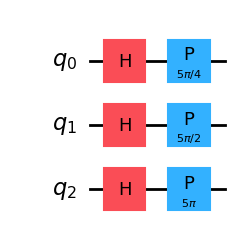

In [18]:
nqubits = 3
number = 5
qc = QuantumCircuit(nqubits)
for qubit in range(nqubits):
    qc.h(qubit)
qc.p(number*pi/4,0)
qc.p(number*pi/2,1)
qc.p(number*pi,2)

qc.draw(output='mpl')

And we can see this does indeed result in the Fourier state $|\widetilde{5}\rangle$:

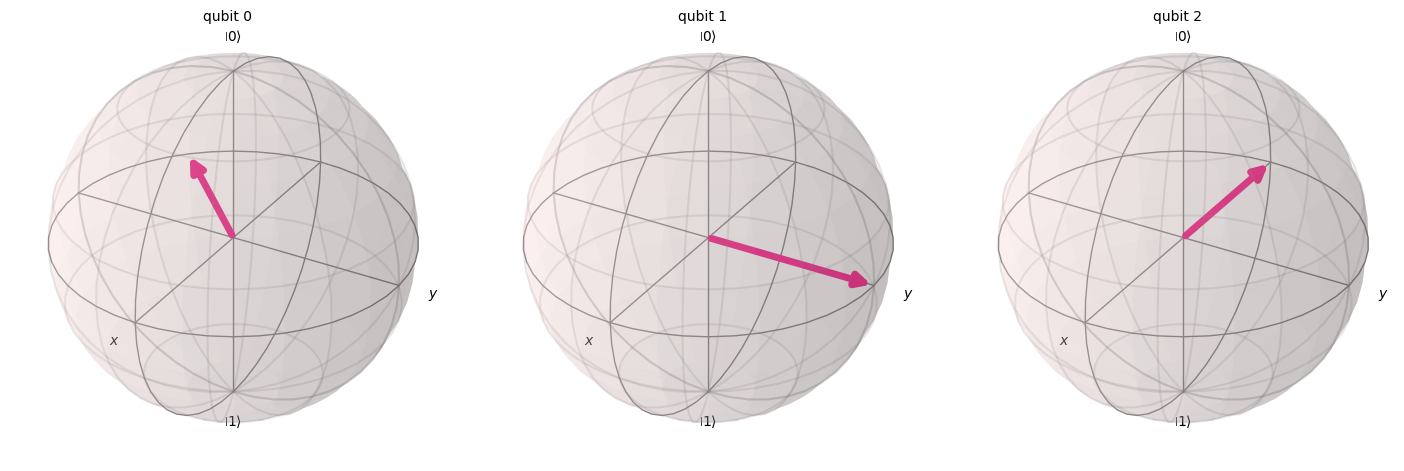

In [19]:
qc_init = qc.copy()
qc_init.save_statevector()
sim = AerSimulator()
statevector = sim.run(qc_init).result().get_statevector()
plot_bloch_multivector(statevector)

Finally, let's apply our inverse QFT:

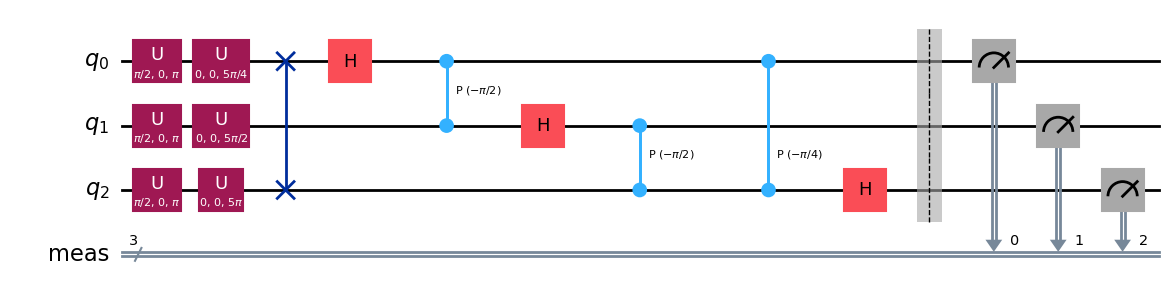

In [20]:
qc = inverse_qft(qc, nqubits)
qc.measure_all()
qc.draw(output='mpl')

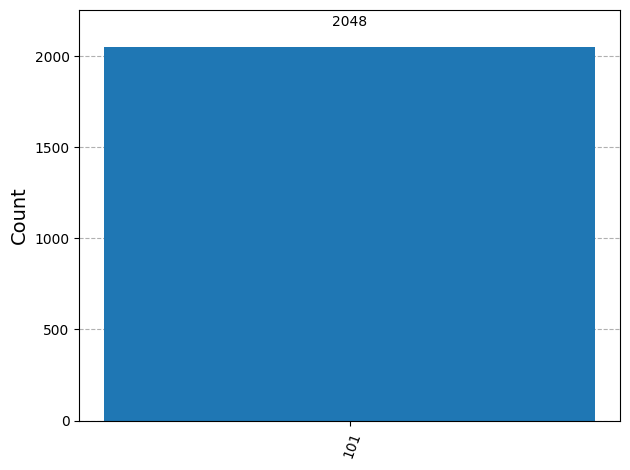

In [21]:
# Run on simulator
sim = AerSimulator()
shots = 2048
transpiled_qc = transpile(qc, sim, optimization_level=3)
result = sim.run(transpiled_qc, shots=shots).result()
counts = result.get_counts()
plot_histogram(counts)

We (hopefully) see that the highest probability outcome is $101$.

## Noisy Simulation

On real quantum hardware, gates are imperfect. We can model this using a **depolarizing noise model**, where each gate has a tunable probability `error_rate` of introducing a random error. We apply this error to all single-qubit and two-qubit gates in the circuit, then compare results across several noise levels.

In [22]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

def build_noise_model(error_rate):
    """Build a depolarizing noise model with tunable error_rate on all gates."""
    noise_model = NoiseModel()
    if error_rate == 0:
        return noise_model

    error_1q = depolarizing_error(error_rate, 1)
    error_2q = depolarizing_error(error_rate, 2)

    for gate in ['h', 'x', 'z', 'p', 's', 't', 'sdg', 'tdg', 'sx', 'rz', 'ry', 'rx', 'id']:
        noise_model.add_all_qubit_quantum_error(error_1q, gate)
    for gate in ['cx', 'cz', 'cp', 'swap', 'ecr', 'rzz', 'rxx']:
        noise_model.add_all_qubit_quantum_error(error_2q, gate)

    return noise_model

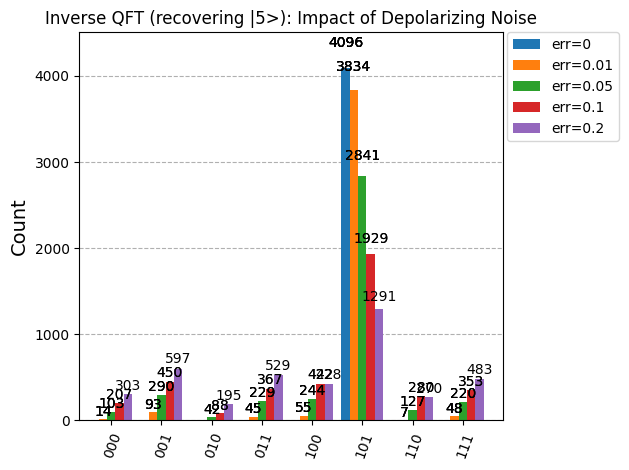

In [23]:
# --- Noisy simulation: Inverse QFT verification ---
error_rates = [0, 0.01, 0.05, 0.1, 0.2]
shots = 4096
noisy_counts = {}

for rate in error_rates:
    noise_model = build_noise_model(rate)
    sim = AerSimulator(noise_model=noise_model)
    t_circ = transpile(qc, sim, optimization_level=3)
    result = sim.run(t_circ, shots=shots).result()
    label = f"err={rate}"
    noisy_counts[label] = result.get_counts()

plot_histogram(list(noisy_counts.values()), legend=list(noisy_counts.keys()),
               title="Inverse QFT (recovering |5>): Impact of Depolarizing Noise")